# Minimal total field in the kernel of the scattering dual

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$ and the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the
variable, as in `maxScatFixQ.ipynb` (without the $Q_W$ constraint).

At copper, the GCD Lagrangian $L^\star = \operatorname{Sym} A(\lambda^\star)$ of the scattering dual has a near-kernel $N$ (orthonormal
eigenvectors with eigenvalues below $\epsilon\,\lambda_\mathrm{max}$). With $S \perp N$ the Lagrangian
$$f_0(x) + \sum_k \lambda_k^\star c_k(x) = D - (x - x^\star)^H L^\star (x - x^\star)$$
is constant on $x = x_r + N y$, where $x_r = (1 - N N^H) x^\star$ is the image part. The kernel component $y$ does not change the scattering dual
objective, so it is chosen by a second QCQP in the kernel: the minimal total field (total voltage) under the same physical constraints,
$$\min_y \|V + x_r + N y\|^2 \quad \text{s.t.} \quad \operatorname{Re}\big(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1\big) = 0, \quad x = x_r + N y .$$
For a perfect conductor the total tangential field vanishes on the metal; for copper it is the small surface-impedance drop.

Steps:
1. global and GCD bounds on the scattered power,
2. the split into image and kernel,
3. the global bound on the minimal field in the kernel ($p = 1$, $p = j$), then GCD in the kernel, and the spectrum of the kernel Lagrangian,
4. pointwise inference and the complex material density of every current.

In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")

cond(Z0) = 6.327e+02


GCD: 36.1s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 8.7e-06, ||c(x*)||/D 2.3e-04, max|w_i|/|I^H V| 4.0e+01
GCD 20: D 1.774054e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 9.3e-14, ||c(x*)||/D 6.4e-03, max|w_i|/|I^H V| 4.1e+01


## Image and kernel

The near-kernel $N$ of the GCD $L^\star$ for several $\epsilon$. Below $\epsilon \approx 10^{-6}$ the Lagrangian is constant on the kernel to
$10^{-4}$ (see `nullSpaceQCQP.ipynb`); at $10^{-4}$ the "kernel" already changes the Lagrangian by about 0.5 %.

eps 1e-06: kernel dimension 9
eps 1e-04: kernel dimension 162


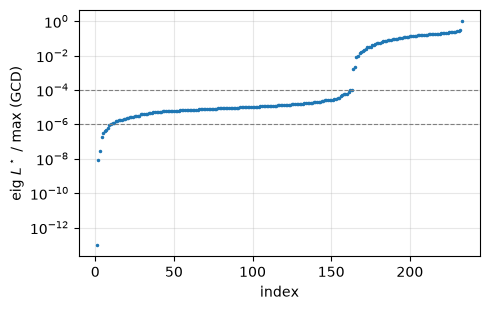

In [6]:
lamGCD, UGCD = np.linalg.eigh(Msym(Qgcd._get_total_A(Qgcd.current_lags)))
kerTols = [1e-6, 1e-4]

def splitKernel(kerTol):
    # kernel N of the GCD L* and the image part x_r of x*
    N = UGCD[:, lamGCD < kerTol*lamGCD[-1]]
    xs = Qgcd.current_xstar
    return N, xs - N @ (N.conj().T @ xs)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.arange(1, Ndes + 1), lamGCD/lamGCD[-1], '.', ms=3)
for t in kerTols:
    ax.axhline(t, ls='--', c='gray', lw=0.8)
    print(f"eps {t:.0e}: kernel dimension {splitKernel(t)[0].shape[1]}")
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max (GCD)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Minimal field in the kernel: global bound and GCD

In $y \in \mathbb C^K$ the field is $F(y) = \|V + x_r + N y\|^2 = y^H y + 2\operatorname{Re}\big(y^H N^H (V + x_r)\big) + \|V + x_r\|^2$ ($N^H N = 1$,
$N^H x_r = 0$). The QCQP maximizes $-F$, so $A_0 = 1$, $s_0 = -N^H V$, $c_0 = -\|V + x_r\|^2$, and its dual $D_F$ gives the lower bound $-D_F$ on the
minimal field. Every projector constraint at $x = x_r + N y$ is a general constraint in $y$ (`projectorForm`, through `shiftForm`). Since
$A_0 = 1 \succ 0$, $\lambda = 0$ is dual feasible.

1. **Global.** The constraints $p = \mathbf 1$ and $p = j\mathbf 1$.
2. **GCD in the kernel.** This is `kernelGCD` of `nullSpaceQCQP.ipynb`. Each iteration evaluates the max-violation and min-eigenvalue
   projectors at $x_r + N y^\star$, orthogonalizes them against the span of the current constraint functions and adds them with
   multiplier 0. Leading constraints are merged once there are too many, and the dual is re-solved.

   The constraint functions of $y$ span at most $(K + 1)^2$ real dimensions. The library dual solver has no iteration limit, so
   `solveReduced` caps the dual evaluations at 3000 and keeps the lowest dual seen. A capped value is not a converged dual.

**Kernel of the kernel problem.** The Lagrangian $1 + \sum_k \lambda_k B_k$ starts positive definite at $\lambda = 0$; its spectrum at the optimum
shows whether the minimal-field problem has a kernel of its own, the same way $L^\star$ did.

The minimal-field bound applies only to currents with the image part $x_r$ fixed. The scattering bound $D$ is still the bound on all
structures.

In [7]:
def qcqpParts(Q):
    # objective (A0, s0, c0) and constraints [(A_k, F_k, c_k)], f(x) = -x^H A x + 2 Re(x^H s) + c
    ck = np.r_[np.zeros(Q.n_proj_constr), Q.c_2j]
    cons = [(Msym(np.asarray(Ak)), Q.Fs[:, k].copy(), ck[k]) for k, Ak in enumerate(Q.precomputed_As)]
    return (Msym(np.asarray(Q.A0)), Q.s0.copy(), float(Q.c0)), cons

def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def consVec(con):
    # real coordinates of the constraint function -y^H B y + 2 Re(y^H s) + c
    B, s, c = con
    return np.r_[B.real.ravel(), B.imag.ravel(), s.real, s.imag, c]

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest |t| in the list that is strictly dual feasible (t < 0 shrinks toward lambda = 0, feasible for A0 > 0). The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, -1e-6, 1e-4, -1e-4, 1e-2, -1e-2, 0.1, -0.1, 1.0, -0.5, 10.0, -1.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

def addConstraint(cons, lags, new, tol=1e-8):
    # new constraint orthogonal to the span of cons, normalized, multiplier 0; dropped if it lies in the span
    M = np.array([consVec(cn) for cn in cons]).T
    v = consVec(new)
    g = np.linalg.lstsq(M, v, rcond=None)[0]
    B, s, c = new
    for gk, (Bk, sk, ck) in zip(g, cons):
        B, s, c = B - gk*Bk, s - gk*sk, c - gk*ck
    nrm = np.linalg.norm(consVec((B, s, c)))
    if nrm < tol*np.linalg.norm(v):
        return cons, lags, False
    return cons + [(B/nrm, s/nrm, c/nrm)], np.r_[lags, 0.0], True

def mergeLead(cons, lags, m):
    # the first m constraints merged by their multipliers into one (normalized), the dual is unchanged
    merged = [sum(l*cn[i] for l, cn in zip(lags[:m], cons[:m])) for i in range(3)]
    nrm = np.linalg.norm(consVec(merged))
    return [tuple(t/nrm for t in merged)] + cons[m:], np.r_[nrm, lags[m:]]

def kernelGCD(Qr, a, B, nIter=20, maxCon=None):
    # GCD inside the kernel x = a + B y of a reduced QCQP with general constraints only
    objective, cons = qcqpParts(Qr)
    maxCon = maxCon or len(cons) + 2*nIter
    hist, added, capped = [Qr.current_dual], 0, 0
    for it in range(nIter):
        lags = Qr.current_lags.copy()
        x = a + B @ Qr.current_xstar
        pV = (2*s1 - A1.conj().T @ x) * np.conj(A2 @ x) # max-violation projector
        u = np.linalg.eigh(Msym(Qr._get_total_A(lags)))[1][:, 0]
        v = B @ u
        pE = (A1.conj().T @ v) * np.conj(A2 @ v) # min-eigenvalue projector, unit modulus
        pE = np.divide(pE, np.abs(pE), out=np.zeros_like(pE), where=np.abs(pE) > 0)
        n0 = len(cons)
        for p in [pV, pE]:
            cons, lags, ok = addConstraint(cons, lags, projectorForm(p, a, B))
        if len(cons) == n0: # both projectors already in the span
            break
        added += len(cons) - n0
        if len(cons) > maxCon:
            cons, lags = mergeLead(cons, lags, len(cons) - maxCon + 1)
        Qr = generalQCQP(objective, cons)
        capped += solveReduced(Qr, lags)[1]
        hist.append(Qr.current_dual)
    return Qr, dict(hist=np.array(hist), added=added, capped=capped)

In [8]:
NgcdKer = 20 # GCD iterations in the kernel
pGlob = [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]

def fieldOf(x):
    return np.linalg.norm(Vinc + x)**2

def kernelReport(name, x, Qk=None):
    # the current in the full space: field, scattering objective and Lagrangian, root GCD residuals, pointwise violation
    e = x - Qgcd.current_xstar
    Lag = Qgcd.current_dual - np.real(e.conj() @ Msym(Qgcd._get_total_A(Qgcd.current_lags)) @ e)
    I = VtoI(x)
    s = (f"    {name:22s}: field / field(x*) {np.sqrt(fieldOf(x)/fieldOf(Qgcd.current_xstar)):.3f}, P/D {evalObj(I)/Qgcd.current_dual:.6f}, "
         f"Lagrangian/D {Lag/Qgcd.current_dual:.6f}, ||c_GCD||/D {np.linalg.norm(constraintRes(Qgcd, x))/Qgcd.current_dual:.1e}, "
         f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")
    if Qk is not None:
        lam = lagSpectrum(Qk)
        s += (f"\n    {'':22s}  bound sqrt(-D_F) / field(x*) {np.sqrt(max(-Qk.current_dual, 0)/fieldOf(Qgcd.current_xstar)):.3f}, "
              f"{Qk.n_gen_constr} constraints, ||c_global||/D {np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual:.1e}, "
              f"kernel Lagrangian min/max eig {lam[0]/lam[-1]:.1e}, near-kernel dim (eps) {np.count_nonzero(lam < kerTol*lam[-1])}")
    print(s)

kernel = {}
for kerTol in kerTols:
    N, xr = splitKernel(kerTol)
    K = N.shape[1]
    objective = (np.eye(K, dtype=complex), -N.conj().T @ Vinc, -fieldOf(xr))
    print(f"eps {kerTol:.0e}, K {K}: unconstrained min field / field(x*) {np.sqrt(fieldOf(xr - N @ (N.conj().T @ Vinc))/fieldOf(Qgcd.current_xstar)):.3f}")
    t1 = time.time()
    Qk = generalQCQP(objective, [projectorForm(p, xr, N) for p in pGlob])
    capG = solveReduced(Qk, np.zeros(2))[1]
    kernelReport("kernel global", xr + N @ Qk.current_xstar, Qk)
    t2 = time.time()
    try:
        Qkg, info = kernelGCD(copy.deepcopy(Qk), xr, N, NgcdKer)
    except np.linalg.LinAlgError as err: # a capped reduced solve can end at extreme multipliers
        print(f"    kernel GCD failed ({err})")
        Qkg, info = None, None
    if Qkg is not None:
        kernelReport(f"kernel GCD ({time.time() - t2:.0f}s)", xr + N @ Qkg.current_xstar, Qkg)
        print(f"    {'':22s}  +{info['added']} constraints, capped solves {int(capG) + info['capped']}, "
              f"bound sqrt(-D_F): global -> GCD {np.sqrt(max(-Qk.current_dual, 0)):.4e} -> {np.sqrt(max(-Qkg.current_dual, 0)):.4e} V")
    kernel[kerTol] = dict(N=N, xr=xr, Qk=Qk, Qkg=Qkg, info=info)

eps 1e-06, K 9: unconstrained min field / field(x*) 0.696


    kernel global         : field / field(x*) 1.358, P/D 0.997814, Lagrangian/D 0.999142, ||c_GCD||/D 2.4e-02, max|w_i|/|I^H V| 7.6e+01
                            bound sqrt(-D_F) / field(x*) 1.358, 2 constraints, ||c_global||/D 4.6e-06, kernel Lagrangian min/max eig 8.6e-02, near-kernel dim (eps) 0


    kernel GCD (14s)      : field / field(x*) 1.447, P/D 1.000167, Lagrangian/D 0.999442, ||c_GCD||/D 3.0e-02, max|w_i|/|I^H V| 7.7e+01
                            bound sqrt(-D_F) / field(x*) 1307.230, 42 constraints, ||c_global||/D 4.5e+00, kernel Lagrangian min/max eig 1.4e-01, near-kernel dim (eps) 0
                            +40 constraints, capped solves 18, bound sqrt(-D_F): global -> GCD 1.0146e+01 -> 9.7658e+03 V
eps 1e-04, K 162: unconstrained min field / field(x*) 0.281


    kernel global         : field / field(x*) 0.665, P/D 0.998899, Lagrangian/D 0.969635, ||c_GCD||/D 9.7e-03, max|w_i|/|I^H V| 2.4e+01
                            bound sqrt(-D_F) / field(x*) 0.665, 2 constraints, ||c_global||/D 8.7e-05, kernel Lagrangian min/max eig 1.8e-04, near-kernel dim (eps) 0


    kernel GCD (34s)      : field / field(x*) 0.939, P/D 0.996333, Lagrangian/D 0.996076, ||c_GCD||/D 1.7e-02, max|w_i|/|I^H V| 4.0e+01
                            bound sqrt(-D_F) / field(x*) 1.288, 42 constraints, ||c_global||/D 2.5e+02, kernel Lagrangian min/max eig 3.8e-12, near-kernel dim (eps) 1
                            +40 constraints, capped solves 0, bound sqrt(-D_F): global -> GCD 4.9669e+00 -> 9.6189e+00 V


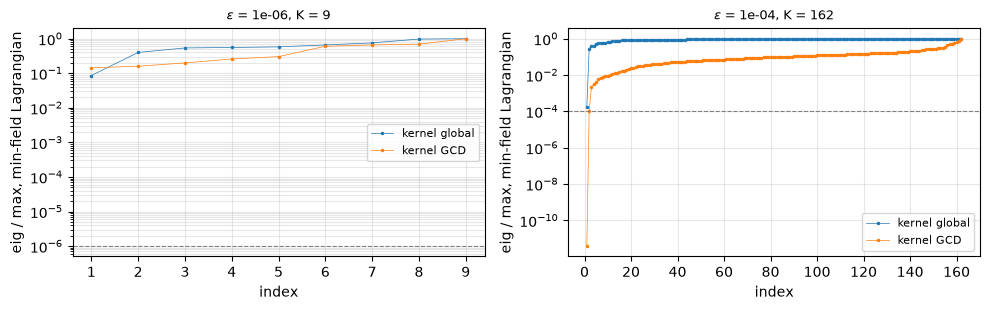

In [9]:
fig, axes = plt.subplots(1, len(kerTols), figsize=(5*len(kerTols), 3.2))
for ax, kerTol in zip(np.atleast_1d(axes), kerTols):
    r = kernel[kerTol]
    for name, Q in [("kernel global", r["Qk"]), ("kernel GCD", r["Qkg"])]:
        if Q is not None:
            lam = lagSpectrum(Q)
            ax.semilogy(np.arange(1, len(lam) + 1), lam/lam[-1], '.-', ms=3, lw=0.5, label=name)
    ax.axhline(kerTol, ls='--', c='gray', lw=0.8)
    ax.set_xlabel('index'); ax.set_ylabel('eig / max, min-field Lagrangian'); ax.set_title(rf"$\epsilon$ = {kerTol:.0e}, K = {r['N'].shape[1]}", fontsize=9)
    ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Pointwise inference and the complex material density

The admittance form of a basis function with relaxed density $d$ is $Z_s L_{ii} I_i = d_i u_i$, where $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$ is the
driving voltage without the material self term. For a given current, the **complex density**
$$d_i = \frac{Z_s L_{ii} I_i}{u_i}$$
is $1$ on metal and $0$ where the basis function is removed: any structure has $\operatorname{Re} d \in \{0, 1\}$ and $\operatorname{Im} d = 0$.

The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance $r_i = (V - Z_\mathrm{tot} I)_i/I_i$ onto the passive ray, $d_i = 1/(1 + t_i)$.

Each relaxed design is rounded with thresholds $t \in [10^{-6}, 1)$, and the binary design with the largest scattered power is kept.

In [10]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    currents = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in currents])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=currents[k], P=Pb[k], th=thsLog[k])

# check: the complex density of the full plate is 1
print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")

currents = {"global x*": Qglob.current_xstar, f"GCD {Ngcd} x*": Qgcd.current_xstar}
for kerTol, r in kernel.items():
    currents[f"kernel global, eps {kerTol:.0e}"] = r["xr"] + r["N"] @ r["Qk"].current_xstar
    if r["Qkg"] is not None:
        currents[f"kernel GCD, eps {kerTol:.0e}"] = r["xr"] + r["N"] @ r["Qkg"].current_xstar

inference = {}
for name, x in currents.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:26s}: Re d quantiles 10/50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(d.real, [0.1, 0.5, 0.9, 1.0]))
          + f", Re d > 0.5: {np.count_nonzero(d.real > 0.5):3d}, median |Im d| {np.median(np.abs(d.imag)):.1e}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W)"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
global x*                 : Re d quantiles 10/50/90/max -2.6e-04/7.5e-07/3.7e-04/1.7e-03, Re d > 0.5:   0, median |Im d| 1.2e-04, impedance form P/D 0.0035 (6.212e-02 W), admittance form P/D 0.0036 (6.465e-02 W)
GCD 20 x*                 : Re d quantiles 10/50/90/max -1.8e-04/-1.0e-05/2.4e-04/4.6e-03, Re d > 0.5:   0, median |Im d| 6.4e-05, impedance form P/D 0.0034 (6.028e-02 W), admittance form P/D 0.0001 (2.202e-03 W)
kernel global, eps 1e-06  : Re d quantiles 10/50/90/max -1.9e-04/-1.4e-05/2.7e-04/1.2e-03, Re d > 0.5:   0, median |Im d| 6.2e-05, impedance form P/D 0.0023 (4.151e-02 W), admittance form P/D 0.0001 (1.025e-03 W)
kernel GCD, eps 1e-06     : Re d quantiles 10/50/90/max -1.9e-04/-8.0e-06/3.4e-04/4.2e-03, Re d > 0.5:   0, median |Im d| 6.8e-05, impedance form P/D 0.0034 (5.997e-02 W), admittance form P/D 0.0001 (2.133e-03 W)


kernel global, eps 1e-04  : Re d quantiles 10/50/90/max -1.2e-04/1.9e-05/1.6e-04/1.8e-03, Re d > 0.5:   0, median |Im d| 4.2e-05, impedance form P/D 0.0025 (4.448e-02 W), admittance form P/D 0.0009 (1.534e-02 W)
kernel GCD, eps 1e-04     : Re d quantiles 10/50/90/max -2.4e-04/-1.4e-05/2.5e-04/1.4e-03, Re d > 0.5:   0, median |Im d| 6.7e-05, impedance form P/D 0.0032 (5.755e-02 W), admittance form P/D 0.0001 (1.011e-03 W)


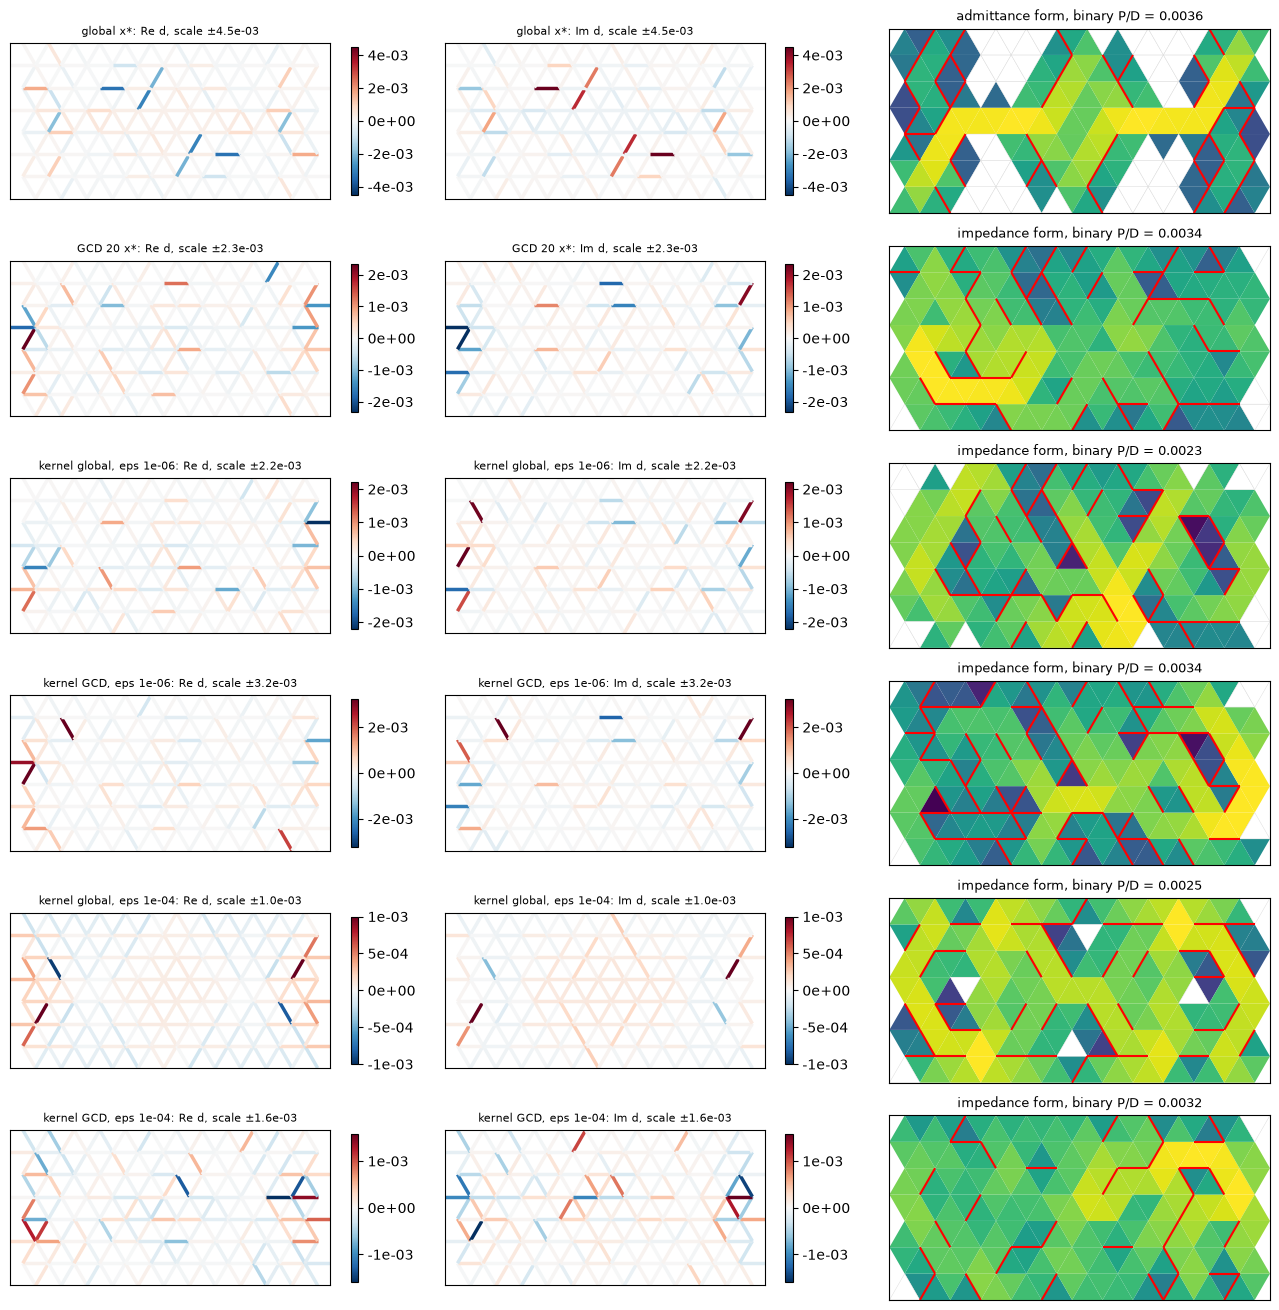

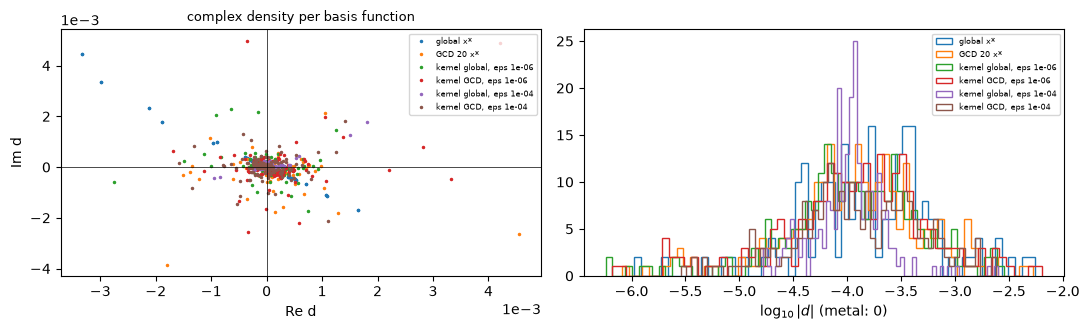

In [11]:
names = list(inference)
fig, axes = plt.subplots(len(names), 3, figsize=(13, 2.2*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[2], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name in names:
    d = inference[name]["d"]
    axes[0].plot(d.real, d.imag, '.', ms=3, label=name)
axes[0].axvline(0, c='k', lw=0.5); axes[0].axhline(0, c='k', lw=0.5); axes[0].ticklabel_format(style='sci', scilimits=(0, 0))
axes[0].set_xlabel('Re d'); axes[0].set_ylabel('Im d'); axes[0].legend(fontsize=6); axes[0].set_title('complex density per basis function', fontsize=9)
for name in names:
    axes[1].hist(np.log10(np.abs(inference[name]["d"])), bins=60, histtype='step', label=name)
axes[1].set_xlabel(r'$\log_{10}|d|$ (metal: 0)'); axes[1].legend(fontsize=6)
plt.tight_layout(); plt.show()

## Conclusions

These are the numbers of this run. GCD is not exactly reproducible (the bound shifts in the fifth digit, and the kernel dimension shifts
between 8 and 9 at $\epsilon = 10^{-6}$), but the conclusions were the same in both complete runs.

**Scattering bounds.** The global bound is 18.48 W and GCD (20 iterations) gives 17.74 W, $1.87\times$ the lossless resonant dipole. The GCD
$L^\star$ has min/max eigenvalue $\sim 10^{-13}$, with a near-kernel of dimension 9 at $\epsilon = 10^{-6}$ and 162 at $10^{-4}$.

**Global bound on the minimal field in the kernel.**
- **No kernel.** The objective $\|V + x\|^2$ has $A_0 = 1 \succ 0$, so the min-field Lagrangian stays definite: min/max eigenvalue $0.09$ ($K = 9$)
  and $2\times10^{-4}$ ($K = 162$). The two-constraint problem is strongly dual: the bound equals the field of its dual current, and the
  global residuals vanish ($\|c\|/D \leq 10^{-4}$).
- **Field values.** The power constraints raise the minimal field well above the unconstrained one, from 0.70 to 1.36 and from 0.28 to 0.67
  (both relative to the field of the GCD $x^\star$).
- **Cost in the scattering Lagrangian.** It stays at $D$ to $10^{-3}$ for $\epsilon = 10^{-6}$ but drops by 3 % for $\epsilon = 10^{-4}$.

**GCD in the kernel.**
- **Small kernel ($K = 9$).** GCD adds 40 constraints and the min-field dual diverges: the bound reaches $\sqrt{-D_F} \approx 1300\times$ the field
  of $x^\star$, and 18 solves hit the cap. The kernel problem with $x_r$ fixed and the GCD constraints is infeasible, as for the scattering
  objective in `nullSpaceQCQP.ipynb`.
- **Large kernel ($K = 162$).** The dual converges to a bound of $1.29\times$ the field of $x^\star$. That bound is above the field of its own dual
  current (0.94), and the current violates the global constraints by $250\,D$.

**Does this problem have a kernel too?** Only after GCD in the large kernel: the min-field Lagrangian then has a 1-dimensional near-kernel
(min/max $4\times10^{-12}$), the same hard case as the scattering dual. The global min-field problem has no kernel.

**Pointwise inference and the complex density.** None of the currents is close to a structure anywhere.
- **Density far below metal.** The complex density $d = Z_s L_{ii} I_i / u_i$ is $|d| \lesssim 5\times10^{-3}$ for every basis function and every
  current, and $\operatorname{Re} d$ and $\operatorname{Im} d$ are of the same size with both signs. Metal requires $d = 1$, so the driving
  voltage $u$ exceeds the copper drop $Z_s L_{ii} I_i$ by three orders of magnitude or more.
- **Weak binary designs.** The pointwise fits give 0.2–0.4 % of the bound (0.04–0.06 W) for all six currents. Minimizing the total field in
  the kernel, globally or with GCD, does not change this.

The kernel is too small, or too constrained, to bring the total field down to the copper level. The solution fits (`nullSpaceMinField`
before this simplification) reached 60–80 % of the bound, because they do not need $d \approx 1$ pointwise.